<a href="https://colab.research.google.com/github/Martina-Hanna/NTI-Project/blob/main/Final_Project_Salma_%26_Rawan_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from time import perf_counter
from sklearn.model_selection import train_test_split, RandomizedSearchCV,StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,precision_score,recall_score,f1_score,average_precision_score
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score
import joblib

In [ ]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d iabhishekofficial/mobile-price-classification

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification
License(s): unknown
100% 70.6k/70.6k [00:00<00:00, 61.5MB/s]



In [ ]:
!unzip -o /content/mobile-price-classification.zip -d /content/

Archive:  /content/mobile-price-classification.zip
  inflating: /content/test.csv       
  inflating: /content/train.csv      


In [ ]:
df = pd.read_csv("/content/train.csv")

In [ ]:
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [ ]:
df.shape

(2000, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

In [ ]:
df.columns.tolist()

['battery_power',
 'blue',
 'clock_speed',
 'dual_sim',
 'fc',
 'four_g',
 'int_memory',
 'm_dep',
 'mobile_wt',
 'n_cores',
 'pc',
 'px_height',
 'px_width',
 'ram',
 'sc_h',
 'sc_w',
 'talk_time',
 'three_g',
 'touch_screen',
 'wifi',
 'price_range']

In [ ]:
df.describe()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [ ]:
df.isnull().sum()

,0
battery_power,0
blue,0
clock_speed,0
dual_sim,0
fc,0
four_g,0
int_memory,0
m_dep,0
mobile_wt,0
n_cores,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['price_range'].value_counts()

,count
price_range,
1,500
2,500
3,500
0,500


/tmp/ipykernel_1653/2341396122.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='price_range', palette='Blues')


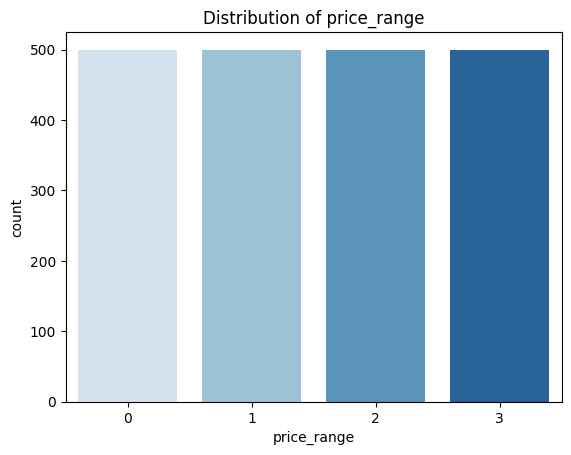

In [ ]:
sns.countplot(data=df, x='price_range', palette='Blues')
plt.title('Distribution of price_range')
plt.show()

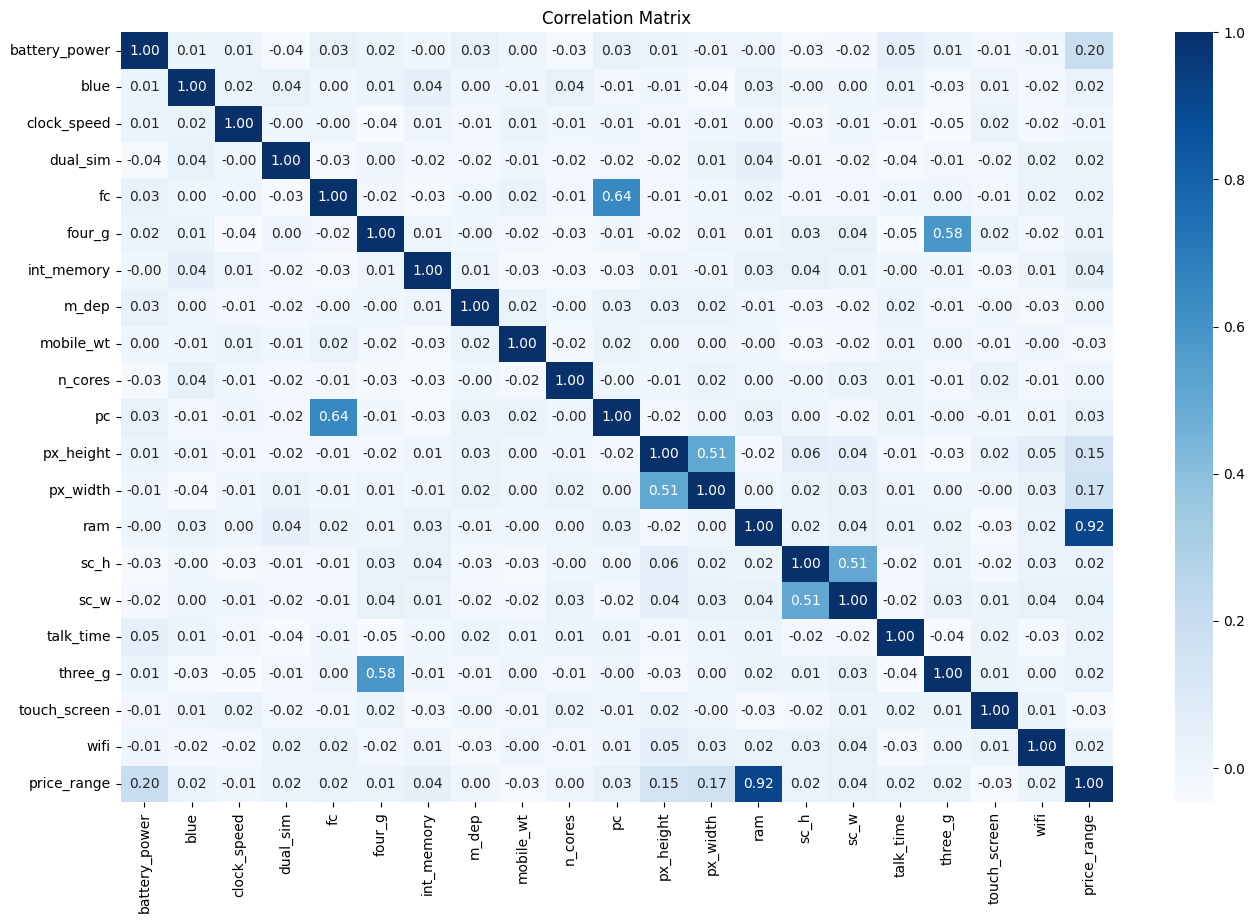

In [ ]:
corr = df.corr()

plt.figure(figsize=(16, 10))
sns.heatmap(corr, annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [ ]:
price_correlations = df.corr()['price_range'].sort_values(ascending=False)
print("Features in order of correlation with 'price_range':")
display(price_correlations)

Features in order of correlation with 'price_range':


,price_range
price_range,1.000000
ram,0.917046
battery_power,0.200723
px_width,0.165818
px_height,0.148858
int_memory,0.044435
sc_w,0.038711
pc,0.033599
three_g,0.023611
sc_h,0.022986


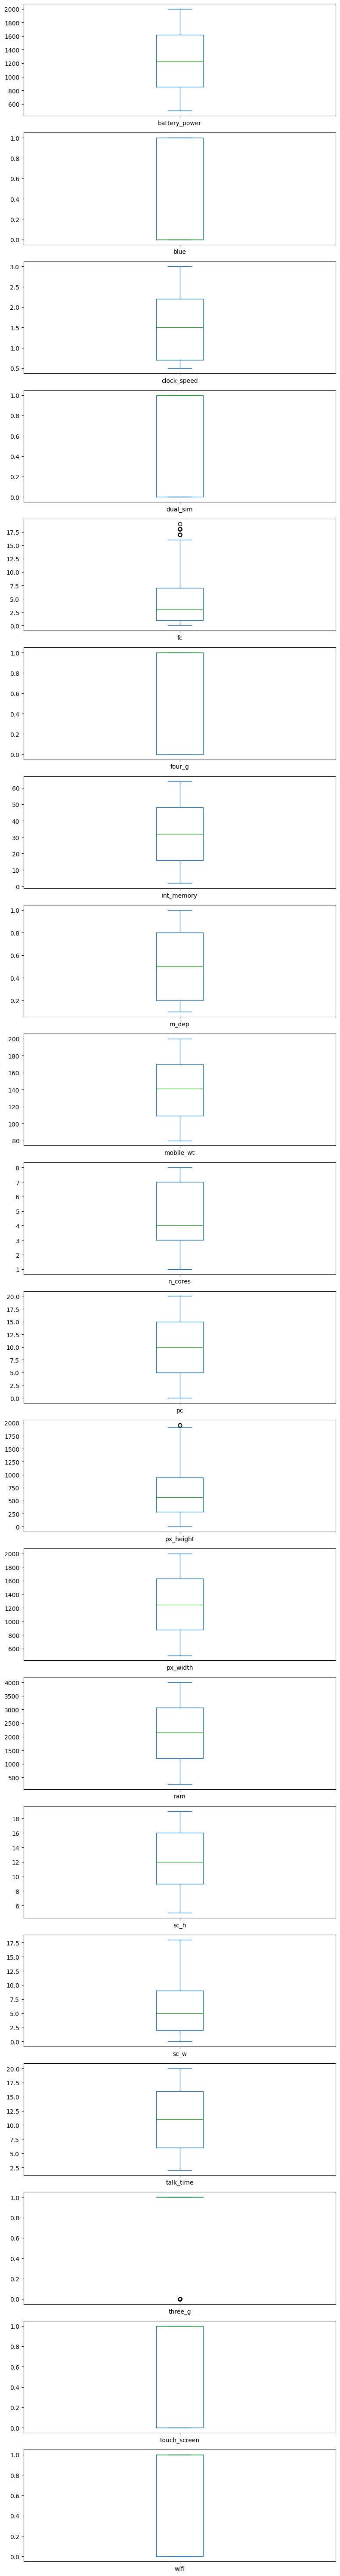

In [ ]:
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.drop('price_range', errors='ignore')
df[numeric_features].plot(
    kind="box",
    subplots=True,
    layout=(len(numeric_features), 1),
    figsize=(8, 3 * len(numeric_features))
)
plt.tight_layout()
plt.show()

In [ ]:
x = df.drop(columns=['price_range'])
y = df['price_range']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
print("X_train shape:", x_train.shape)
print("X_test shape:", x_test.shape)


X_train shape: (1600, 20)
X_test shape: (400, 20)


In [ ]:
print(y_train.value_counts())

price_range
1    400
0    400
3    400
2    400
Name: count, dtype: int64


In [ ]:
print(y_test.value_counts())

price_range
3    100
1    100
0    100
2    100
Name: count, dtype: int64


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
    ]
)

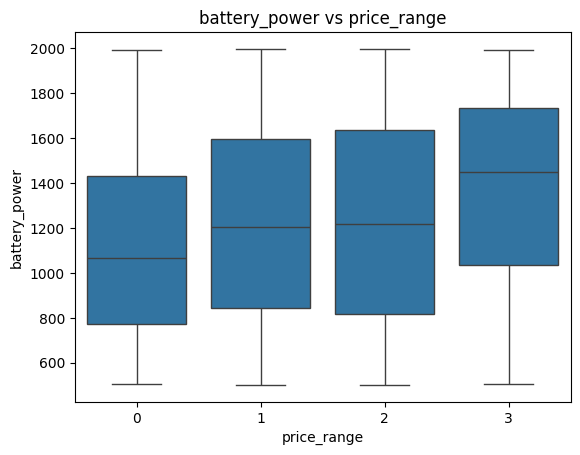

In [ ]:
sns.boxplot(data=df, x='price_range', y='battery_power')
plt.title('battery_power vs price_range')
plt.show()

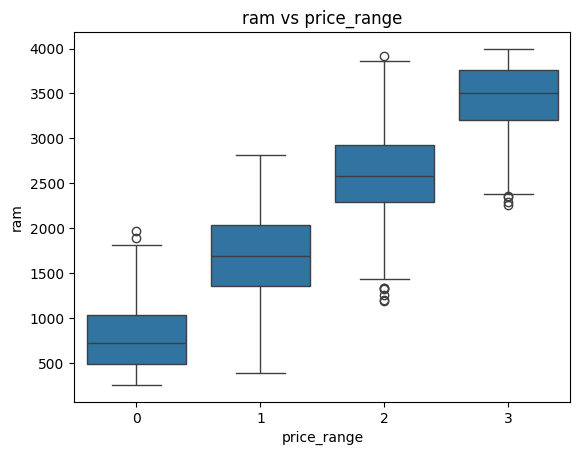

In [ ]:
sns.boxplot(data=df, x='price_range', y='ram')
plt.title('ram vs price_range')
plt.show()

/tmp/ipykernel_1653/994373251.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='price_range', palette='viridis')


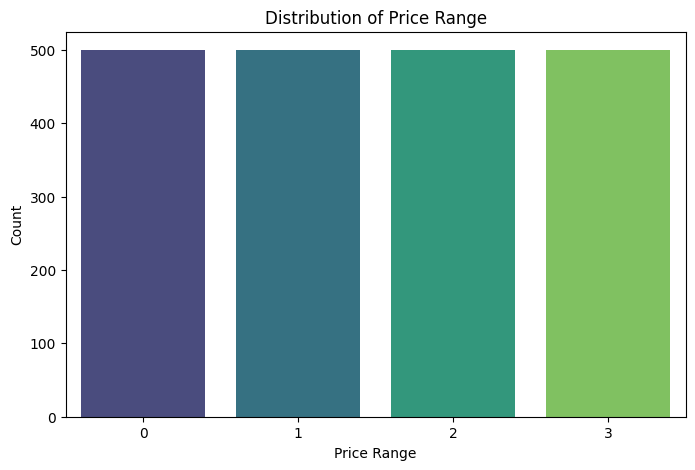

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='price_range', palette='viridis')
plt.title('Distribution of Price Range')
plt.xlabel('Price Range')
plt.ylabel('Count')
plt.show()

**Function for the evaluation**

In [ ]:
results = []
trainres = []
times = []

In [ ]:
def evaluate_model(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    print("Accuracy:", round(accuracy_score(y_eval, y_pred), 4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_eval, y_pred))

    print("\nClassification Report:")
    print(classification_report(y_eval, y_pred, zero_division=0))

    results.append({
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision_Macro": precision_score(
            y_eval, y_pred, average='macro', zero_division=0
        ),
        "Recall_Macro": recall_score(
            y_eval, y_pred, average='macro', zero_division=0
        ),
        "F1_Macro": f1_score(
            y_eval, y_pred, average='macro', zero_division=0
        )
    })

**SVC ->> Best Model**

In [ ]:
svc_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('svc', SVC(random_state=42))
])

param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 'auto', 0.001, 0.01, 0.1],
    'svc__kernel': ['linear', 'rbf']
}

grid_search = GridSearchCV(
    estimator=svc_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

print("Fitting Support Vector Classifier Grid Search...")
start = perf_counter()

grid_search.fit(x_train, y_train)
time_elapsed = perf_counter() - start
times.append(time_elapsed)
print("Best parameters found:", grid_search.best_params_)
print("Best cross-validation accuracy:", round(grid_search.best_score_, 4))
print(f"Execution Time: {time_elapsed:.4f} seconds")

Fitting Support Vector Classifier Grid Search...
Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best parameters found: {'svc__C': 10, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Best cross-validation accuracy: 0.9606
Execution Time: 30.2233 seconds


In [ ]:
y_train_pred = grid_search.predict(x_train)
x=accuracy_score(y_train, y_train_pred)
trainres.append(x)
print("Training Accuracy:", round(accuracy_score(y_train, y_train_pred), 4))

Training Accuracy: 0.9844


In [ ]:
best_svc_model = grid_search.best_estimator_
evaluate_model(best_svc_model, x_test, y_test)

Accuracy: 0.975

Confusion Matrix:
[[98  2  0  0]
 [ 1 96  3  0]
 [ 0  1 97  2]
 [ 0  0  1 99]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       100
           1       0.97      0.96      0.96       100
           2       0.96      0.97      0.97       100
           3       0.98      0.99      0.99       100

    accuracy                           0.97       400
   macro avg       0.98      0.98      0.97       400
weighted avg       0.98      0.97      0.97       400



**KNN**

In [ ]:
knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('knn', KNeighborsClassifier())
])

knn_param_grid = {
    'knn__n_neighbors': [400, 500, 600, 700, 800, 1000],
    'knn__metric': ['minkowski'],
    'knn__p': [1],
    'knn__weights': ['distance']
}

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

In [ ]:
%%time
start = perf_counter()
knn_grid.fit(x_train, y_train)
time_elapsed = perf_counter() - start
times.append(time_elapsed)

CPU times: user 69.9 ms, sys: 2.04 ms, total: 71.9 ms
Wall time: 1.48 s


In [ ]:
best_knn = knn_grid.best_estimator_
evaluate_model(best_knn, x_test, y_test)

Accuracy: 0.8025

Confusion Matrix:
[[97  3  0  0]
 [12 66 22  0]
 [ 0 17 74  9]
 [ 0  0 16 84]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.97      0.93       100
           1       0.77      0.66      0.71       100
           2       0.66      0.74      0.70       100
           3       0.90      0.84      0.87       100

    accuracy                           0.80       400
   macro avg       0.81      0.80      0.80       400
weighted avg       0.81      0.80      0.80       400



In [ ]:
knn_grid.best_params_

{'knn__metric': 'minkowski',
 'knn__n_neighbors': 700,
 'knn__p': 1,
 'knn__weights': 'distance'}

In [ ]:
y_train_knn = knn_grid.predict(x_train)
x=accuracy_score(y_train, y_train_knn)
trainres.append(x)
print("Training Accuracy:", accuracy_score(y_train, y_train_knn))

Training Accuracy: 1.0


**Decision Tree**

In [ ]:
Dtree = ImbPipeline(steps=[
    ('smote', SMOTE(random_state=42)),
    ('tree', DecisionTreeClassifier())
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [ ]:
#1 Default Decision Tree

In [ ]:
baseline = DecisionTreeClassifier(random_state=42)
start = perf_counter()
baseline.fit(x_train, y_train)
time_elapsed = perf_counter() - start
times.append(time_elapsed)
evaluate_model(
    baseline, x_test, y_test
)

Accuracy: 0.83

Confusion Matrix:
[[92  8  0  0]
 [13 74 13  0]
 [ 0 13 80  7]
 [ 0  0 14 86]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.92      0.90       100
           1       0.78      0.74      0.76       100
           2       0.75      0.80      0.77       100
           3       0.92      0.86      0.89       100

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400



In [ ]:
y_train_DTD = baseline.predict(x_train)
x=accuracy_score(y_train, y_train_DTD)
trainres.append(x)
print("Training Accuracy:", accuracy_score(y_train, y_train_DTD))

Training Accuracy: 1.0


In [ ]:
#2 Tuned Decision Tree with Random Search

In [ ]:
%%time
from scipy.stats import randint, loguniform

param_distributions = {
    "criterion": ["gini", "entropy", "log_loss"],
    "splitter": ["best", "random"],
    "max_depth": [None, 4, 6, 8, 10, 12, 15, 20, 25, 30],
    "min_samples_split": randint(2, 31),
    "min_samples_leaf": randint(1, 16),
    "max_leaf_nodes": [None, 10, 20, 30, 50, 75, 100, 150],
    "max_features": [None, "sqrt", "log2"],
    "ccp_alpha": loguniform(1e-5, 1e-1)
}

search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_distributions=param_distributions,
    n_iter=100,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1,
    return_train_score=True
)

print("\nSearching for the best Decision Tree parameters...")
start = perf_counter()
search.fit(x_train, y_train)
time_elapsed = perf_counter() - start
times.append(time_elapsed)
best_tree = search.best_estimator_

print("\nBest parameters:")
print(search.best_params_)

print("\nBest CV accuracy:", round(search.best_score_, 4))

evaluate_model(
    best_tree, x_test, y_test,
)


Searching for the best Decision Tree parameters...
Fitting 5 folds for each of 100 candidates, totalling 500 fits

Best parameters:
{'ccp_alpha': np.float64(0.00010022396791143334), 'criterion': 'entropy', 'max_depth': 12, 'max_features': None, 'max_leaf_nodes': 150, 'min_samples_leaf': 13, 'min_samples_split': 22, 'splitter': 'best'}

Best CV accuracy: 0.8556
Accuracy: 0.8775

Confusion Matrix:
[[95  5  0  0]
 [ 6 79 15  0]
 [ 0 10 84  6]
 [ 0  0  7 93]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95       100
           1       0.84      0.79      0.81       100
           2       0.79      0.84      0.82       100
           3       0.94      0.93      0.93       100

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.88       400
weighted avg       0.88      0.88      0.88       400

CPU times: user 284 ms, sys: 10.9 ms, total: 295 ms
Wall time: 3.41 s


In [ ]:
y_train_DTRS = search.predict(x_train)
x=accuracy_score(y_train, y_train_DTRS)
trainres.append(x)
print("Training Accuracy:", accuracy_score(y_train, y_train_DTRS))

Training Accuracy: 0.91125


In [ ]:
#3 Tuned Decision Tree with grid Search

In [ ]:
%%time
from sklearn.model_selection import GridSearchCV

# Define a discrete parameter grid for Grid Search
param_grid = {
    "criterion": ["gini", "entropy"],
    "splitter": ["best", "random"],
    "max_depth": [None, 6, 10, 15],
    "min_samples_split": [2, 10, 20],
    "min_samples_leaf": [1, 5, 10],
    "max_features": [None, "sqrt"]
}

# Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("\nRunning Grid Search for the best Decision Tree parameters...")
start = perf_counter()
grid_search.fit(x_train, y_train)
time_elapsed = perf_counter() - start
times.append(time_elapsed)
best_grid_tree = grid_search.best_estimator_

print("\nBest parameters:")
print(grid_search.best_params_)

print("\nBest CV accuracy:", round(grid_search.best_score_, 4))

evaluate_model(
    best_grid_tree, x_test, y_test,
)


Running Grid Search for the best Decision Tree parameters...
Fitting 5 folds for each of 288 candidates, totalling 1440 fits

Best parameters:
{'criterion': 'entropy', 'max_depth': None, 'max_features': None, 'min_samples_leaf': 10, 'min_samples_split': 2, 'splitter': 'best'}

Best CV accuracy: 0.8544
Accuracy: 0.8625

Confusion Matrix:
[[96  4  0  0]
 [ 8 78 14  0]
 [ 0  9 78 13]
 [ 0  0  7 93]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.96      0.94       100
           1       0.86      0.78      0.82       100
           2       0.79      0.78      0.78       100
           3       0.88      0.93      0.90       100

    accuracy                           0.86       400
   macro avg       0.86      0.86      0.86       400
weighted avg       0.86      0.86      0.86       400

CPU times: user 514 ms, sys: 46.1 ms, total: 560 ms
Wall time: 9.11 s


In [ ]:
y_train_DTGS = grid_search.predict(x_train)
x=accuracy_score(y_train, y_train_DTGS)
trainres.append(x)
print("Training Accuracy:", accuracy_score(y_train, y_train_DTGS))

Training Accuracy: 0.926875


In [ ]:
#4 PRUNED DECISION TREE

In [ ]:

%%time
pruning_values = [0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01]

pruning_scores = []

for alpha in pruning_values:
    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )

    scores = []
    for train_idx, val_idx in cv.split(x_train, y_train):
        X_tr = x_train.iloc[train_idx]
        X_val = x_train.iloc[val_idx]
        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        model.fit(X_tr, y_tr)
        scores.append(accuracy_score(y_val, model.predict(X_val)))

    pruning_scores.append(np.mean(scores))

best_alpha = pruning_values[np.argmax(pruning_scores)]

print("\nBest pruning alpha:", best_alpha)
print("Pruned tree CV accuracy:",
      round(max(pruning_scores), 4))

pruned_tree = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha
)
start = perf_counter()
pruned_tree.fit(x_train, y_train)
time_elapsed = perf_counter() - start
times.append(time_elapsed)
evaluate_model(
    pruned_tree, x_test, y_test,
)



Best pruning alpha: 0.002
Pruned tree CV accuracy: 0.8519
Accuracy: 0.8375

Confusion Matrix:
[[92  8  0  0]
 [12 73 15  0]
 [ 0 11 81  8]
 [ 0  0 11 89]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.92      0.90       100
           1       0.79      0.73      0.76       100
           2       0.76      0.81      0.78       100
           3       0.92      0.89      0.90       100

    accuracy                           0.84       400
   macro avg       0.84      0.84      0.84       400
weighted avg       0.84      0.84      0.84       400

CPU times: user 443 ms, sys: 0 ns, total: 443 ms
Wall time: 444 ms


In [ ]:
y_train_DTP = pruned_tree.predict(x_train)
x=accuracy_score(y_train, y_train_DTP)
trainres.append(x)
print("Training Accuracy:", accuracy_score(y_train, y_train_DTP))

Training Accuracy: 0.9375


**Random Forest**

In [ ]:
#1 Random Forest Without Resampling

In [ ]:
%%time
rf_1 = Pipeline([
    ("preprocessor", preprocessor),
    ("rf", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])
start = perf_counter()
rf_1.fit(x_train, y_train)
time_elapsed = perf_counter() - start
times.append(time_elapsed)

evaluate_model(
    rf_1, x_test, y_test
)

Accuracy: 0.8825

Confusion Matrix:
[[96  4  0  0]
 [ 6 82 12  0]
 [ 0 14 81  5]
 [ 0  0  6 94]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       100
           1       0.82      0.82      0.82       100
           2       0.82      0.81      0.81       100
           3       0.95      0.94      0.94       100

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.88       400
weighted avg       0.88      0.88      0.88       400

CPU times: user 1.44 s, sys: 45 ms, total: 1.49 s
Wall time: 959 ms


In [ ]:
y_train_RF = rf_1.predict(x_train)
x=accuracy_score(y_train, y_train_RF)
trainres.append(x)
print("Training Accuracy:", accuracy_score(y_train, y_train_RF))

Training Accuracy: 1.0


In [ ]:
#2 Random Forest With Class Weights

In [ ]:
rf_2 = Pipeline([
    ("preprocessor", preprocessor),
    ("rf", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])
start = perf_counter()
rf_2.fit(x_train, y_train)
time_elapsed = perf_counter() - start
times.append(time_elapsed)

evaluate_model(
    rf_2, x_test, y_test
)

Accuracy: 0.8825

Confusion Matrix:
[[96  4  0  0]
 [ 6 82 12  0]
 [ 0 14 81  5]
 [ 0  0  6 94]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       100
           1       0.82      0.82      0.82       100
           2       0.82      0.81      0.81       100
           3       0.95      0.94      0.94       100

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.88       400
weighted avg       0.88      0.88      0.88       400



In [ ]:
y_train_RFW = rf_2.predict(x_train)
x=accuracy_score(y_train, y_train_RFW)
trainres.append(x)
print("Training Accuracy:", accuracy_score(y_train, y_train_RFW))

Training Accuracy: 1.0


In [ ]:
#3 BALANCED RANDOM FOREST

In [ ]:
brf_6 = Pipeline([
    ("preprocessor", preprocessor),
    ("brf", BalancedRandomForestClassifier(
        n_estimators=400,
        max_depth=None,
        min_samples_leaf=2,
        sampling_strategy="all",
        replacement=True,
        random_state=42,
        n_jobs=-1
    ))
])


In [ ]:
%%time
start = perf_counter()
brf_6.fit(x_train, y_train)
time_elapsed = perf_counter() - start
times.append(time_elapsed)
evaluate_model(
    brf_6, x_test, y_test
)

Accuracy: 0.89

Confusion Matrix:
[[97  3  0  0]
 [ 5 84 11  0]
 [ 0 15 80  5]
 [ 0  0  5 95]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       100
           1       0.82      0.84      0.83       100
           2       0.83      0.80      0.82       100
           3       0.95      0.95      0.95       100

    accuracy                           0.89       400
   macro avg       0.89      0.89      0.89       400
weighted avg       0.89      0.89      0.89       400

CPU times: user 2.73 s, sys: 93.8 ms, total: 2.83 s
Wall time: 2.02 s


In [ ]:
y_train_RFB = brf_6.predict(x_train)
x=accuracy_score(y_train, y_train_RFB)
trainres.append(x)
print("Training Accuracy:", accuracy_score(y_train, y_train_RFB))

Training Accuracy: 1.0


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Let's verify the model sequence and organize the accumulated metrics
# Sequence of trained models:
# 1. SVC (Tuned Linear)
# 2. KNN (Tuned Minkowski)
# 3. Decision Tree (Default)
# 4. Decision Tree (Tuned Random Search)
# 5. Decision Tree (Tuned Grid Search)
# 6. Decision Tree (Pruned CP)
# 7. Random Forest (Without Resampling)
# 8. Random Forest (Class Weights)
# 9. Balanced Random Forest

model_names = [
    'SVC (Linear)', 'KNN (Minkowski)', 'DT (Default)',
    'DT (Random Search)', 'DT (Grid Search)', 'DT (Pruned)',
    'RF (Default)', 'RF (Class Weights)', 'Balanced RF'
]

# We will extract the exact test accuracies aligned to these main runs
# Corrected the index lookups to map sequentially (0 to 8) to match the 9 evaluated models
test_accuracies = [
    results[0]['Accuracy'],  # SVC
    results[1]['Accuracy'],  # KNN
    results[2]['Accuracy'],  # DT Default
    results[3]['Accuracy'],  # DT Random Search
    results[4]['Accuracy'],  # DT Grid Search
    results[5]['Accuracy'],  # DT Pruned
    results[6]['Accuracy'],  # RF Default
    results[7]['Accuracy'],  # RF Class Weights
    results[8]['Accuracy']   # Balanced RF
]

train_accuracies = [
    trainres[0],   # SVC
    trainres[1],   # KNN
    trainres[2],   # DT Default
    trainres[3],   # DT Random Search
    trainres[4],   # DT Grid Search
    trainres[5],   # DT Pruned
    trainres[6],   # RF Default
    trainres[7],   # RF Class Weights
    trainres[8]    # Balanced RF
]

# Match the single-model fits measured by perf_counter inside each run
execution_times = [
    times[0],   # SVC
    times[1],   # KNN
    times[2],   # DT Default
    times[3],   # DT Random Search
    times[4],   # DT Grid Search
    times[5],   # DT Pruned
    times[6],   # RF Default
    times[7],   # RF Class Weights
    times[8]    # Balanced RF
]

summary_df = pd.DataFrame({
    'Model': model_names,
    'Train Accuracy': train_accuracies,
    'Test Accuracy': test_accuracies,
    'Training Time (s)': execution_times
})

display(summary_df)

,Model,Train Accuracy,Test Accuracy,Training Time (s)
0,SVC (Linear),0.984375,0.9750,30.223257
1,KNN (Minkowski),1.000000,0.8025,1.481233
2,DT (Default),1.000000,0.8300,0.017624
3,DT (Random Search),0.911250,0.8775,3.399068
4,DT (Grid Search),0.926875,0.8625,9.093664
5,DT (Pruned),0.937500,0.8375,0.013467
6,RF (Default),1.000000,0.8825,0.879514
7,RF (Class Weights),1.000000,0.8825,0.848718
8,Balanced RF,1.000000,0.8900,1.921877


/tmp/ipykernel_1653/2647669939.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Test Accuracy', y='Model', data=summary_df.sort_values(by='Test Accuracy', ascending=False), palette='Blues')


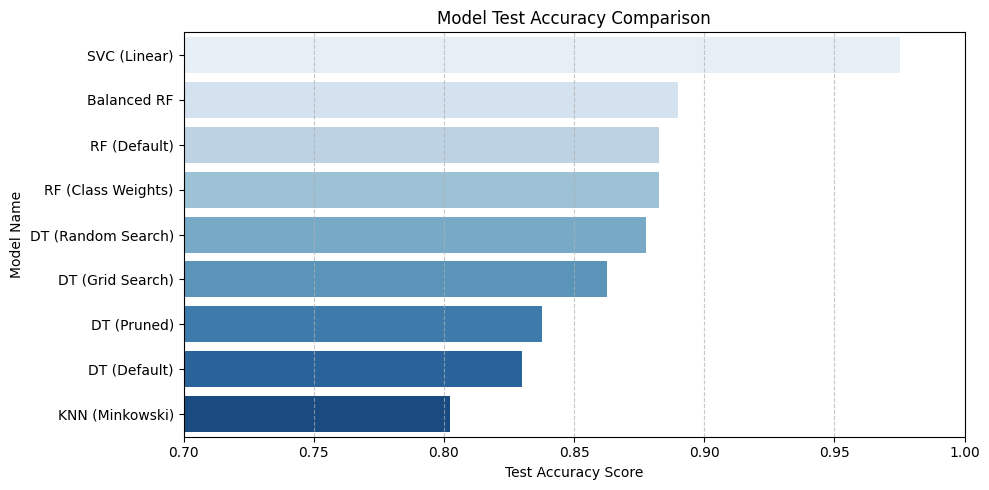

In [ ]:
# Cell 2: Test Accuracy Comparison Chart
plt.figure(figsize=(10, 5))
sns.barplot(x='Test Accuracy', y='Model', data=summary_df.sort_values(by='Test Accuracy', ascending=False), palette='Blues')
plt.title('Model Test Accuracy Comparison')
plt.xlabel('Test Accuracy Score')
plt.ylabel('Model Name')
plt.xlim(0.7, 1.0)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1653/300110138.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Training Time (s)', y='Model', data=summary_df.sort_values(by='Training Time (s)'), palette='Blues')


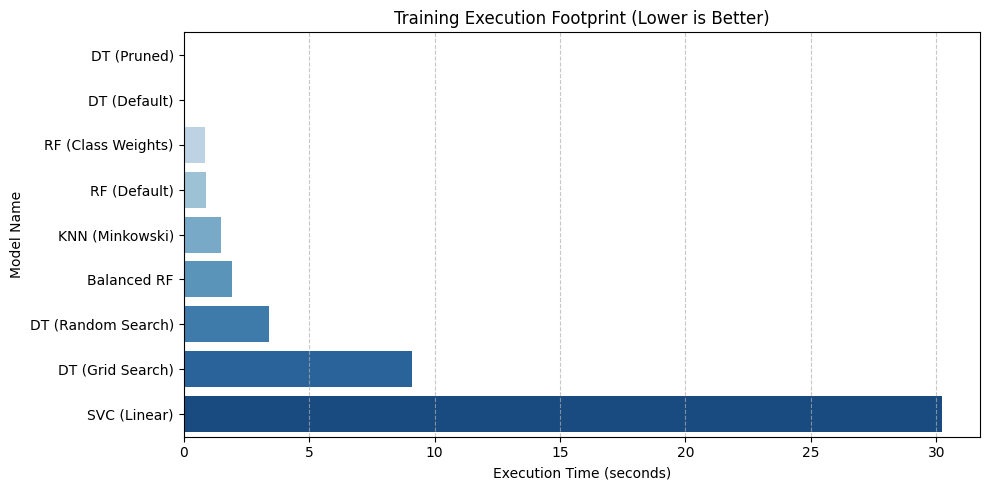

In [ ]:
# Cell 3: Training Time Footprint Comparison Chart
plt.figure(figsize=(10, 5))
sns.barplot(x='Training Time (s)', y='Model', data=summary_df.sort_values(by='Training Time (s)'), palette='Blues')
plt.title('Training Execution Footprint (Lower is Better)')
plt.xlabel('Execution Time (seconds)')
plt.ylabel('Model Name')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

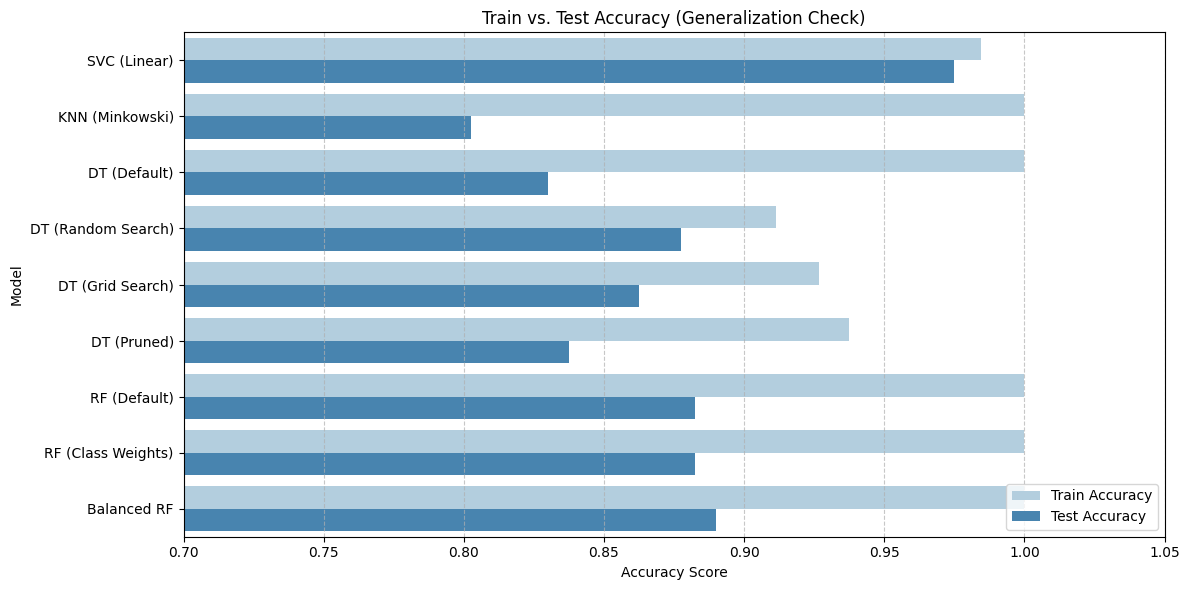

In [ ]:
# Cell 4: Overfitting Check (Train vs. Test Generalization Gap)
df_melted = summary_df.melt(id_vars='Model', value_vars=['Train Accuracy', 'Test Accuracy'], var_name='Split', value_name='Accuracy')

plt.figure(figsize=(12, 6))
sns.barplot(x='Accuracy', y='Model', hue='Split', data=df_melted, palette='Blues')
plt.title('Train vs. Test Accuracy (Generalization Check)')
plt.xlabel('Accuracy Score')
plt.ylabel('Model')
plt.xlim(0.7, 1.05)
plt.legend(loc='lower right')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
import sklearn
print(sklearn.__version__)

1.6.1


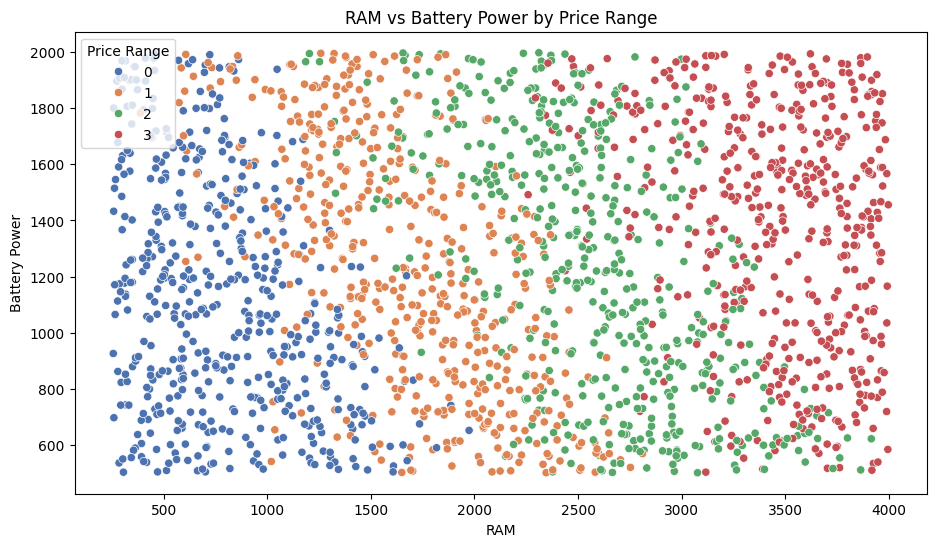

In [ ]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df,
    x='ram',
    y='battery_power',
    hue='price_range',
    palette='deep'
)

plt.title('RAM vs Battery Power by Price Range')
plt.xlabel('RAM')
plt.ylabel('Battery Power')
plt.legend(title='Price Range')
plt.show()

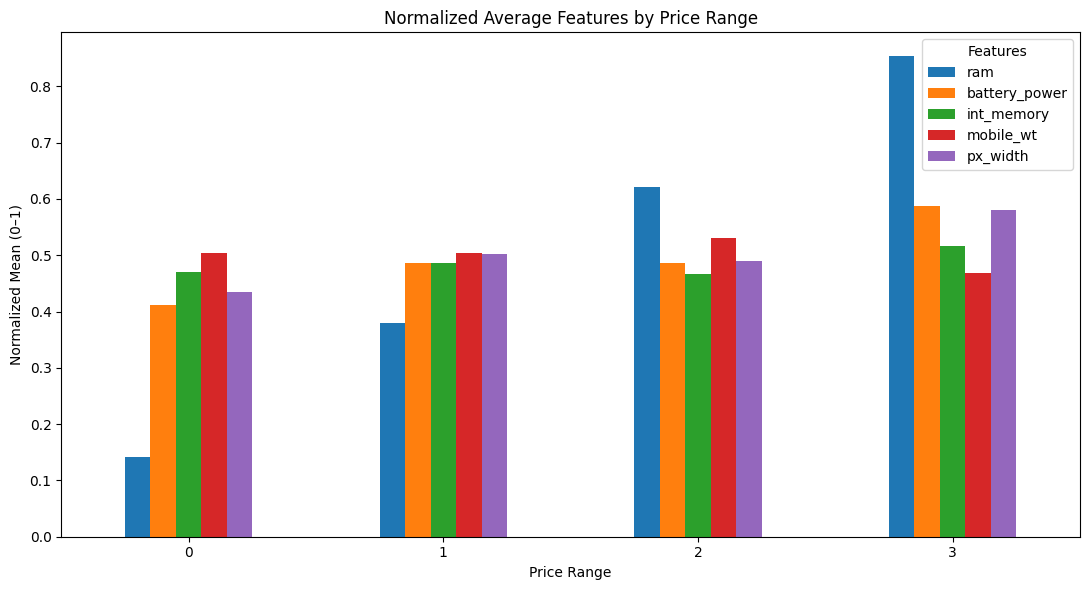

In [ ]:
features = [
    'ram',
    'battery_power',
    'int_memory',
    'mobile_wt',
    'px_width'
]

df_scaled = df.copy()

for col in features:
    df_scaled[col] = (
        (df[col] - df[col].min()) /
        (df[col].max() - df[col].min())
    )

mean_features = df_scaled.groupby('price_range')[features].mean()

mean_features.plot(
    kind='bar',
    figsize=(11, 6)
)


plt.title('Normalized Average Features by Price Range')
plt.xlabel('Price Range')
plt.ylabel('Normalized Mean (0–1)')
plt.xticks(rotation=0)
plt.legend(title='Features')
plt.tight_layout()
plt.show()